# Desigualdad en la supervivencia del Titanic según clase del pasaje

**MCDI503 · Exploración Inteligente para la Ciencia de Datos · Fase 1 sumativa**

## I. Identificación del proyecto

**Grupo 2** · Cristian Andrés Hurtado Cabezas, Jorge Altamirano, Renzo Vilchez y Luis Paredes.

**Datos.** Titanic, versión de Seaborn. Cada fila representa un registro de pasajero.

**Propósito.** Medir la brecha de supervivencia entre clases del pasaje y examinar cómo se manifiesta por sexo registrado. El diagnóstico de las edades faltantes delimita el alcance de la exploración por edad.

### Cómo ejecutar este notebook en VS Code

1. Abre la carpeta completa `titanic-eda` con las extensiones **Python** y **Jupyter** habilitadas. Deben quedar juntos este `.ipynb`, `requirements.txt` y `data/raw/titanic.csv`.
2. En otro PC, crea la `.venv` en la carpeta del proyecto usando Python **3.13.5** e instala las versiones de `requirements.txt`. En la terminal PowerShell de VS Code, comprueba primero que `python --version` muestra `Python 3.13.5`. Si muestra otro Python, sustituye `python` por `& 'C:\ruta\al\python.exe'` en el comando que crea la `.venv`, con la ruta de tu Python 3.13.5.

   ```powershell
   python -m venv .venv
   .\.venv\Scripts\python.exe -m pip install -r requirements.txt
   ```

3. En el notebook, abre **Select Kernel → Select Another Kernel… → Python Environments…**. Si el menú ya muestra **Python Environments…**, entra directamente. Elige la fila cuya ruta termina en `titanic-eda\.venv\Scripts\python.exe`. Si no aparece, abre **Ctrl+Shift+P → Python: Select Interpreter → Enter interpreter path…**, indica la ruta completa a ese `.venv\Scripts\python.exe` y vuelve al selector del notebook.
4. Pulsa **Run All**. La primera celda debe mostrar **Python activo: 3.13.5** y **OK** en las seis librerías. Guarda el notebook para conservar las salidas.

**Entorno local ya probado.** En el PC donde se validó esta entrega, la misma lista muestra **base (Python 3.13.5)** con ruta `~\anaconda3\python.exe`. Ese kernel tiene las seis versiones fijadas y ejecutó todas las celdas. Al seleccionarlo, el aviso de que el intérprete difiere de la `.venv` es esperado. En otros equipos, usa la `.venv` del proyecto o comprueba las versiones antes de elegir otro `base`.

El [README](README.md) recoge los mismos pasos y explica la validación del CSV.

## II. Contexto y objetivo exploratorio

Los testimonios de pasajeros y los estudios sobre el naufragio motivan una hipótesis histórica: las diferencias en el acceso a la cubierta de botes pudieron contribuir a la menor supervivencia de tercera clase. El Titanic de Seaborn permite examinar esa diferencia porque registra la clase del pasaje y el desenlace por pasajero, además del sexo y la edad. Usamos la clase como indicador indirecto de posición económica. Esta fase se limita a describir asociaciones en los 891 registros y evaluar la cobertura de la edad para orientar la exploración posterior.

1. **P1.** ¿Cuál fue la diferencia de supervivencia entre las tres clases en los registros de Seaborn?
2. **P2.** ¿Cómo varió esa diferencia dentro de cada categoría de sexo registrado?
3. **P3.** ¿Qué muestra la edad observada según supervivencia y cómo condicionan la comparación los faltantes de edad por clase y desenlace?

La sección VI presenta denominadores, tasas y brechas para P1 y P2 (tablas 1–3), y la cobertura y las medianas de edad para P3 (tablas 4–5). Los testimonios de 1912 y la revisión de Hall (1986) aportan contexto para la discusión.

## III. Carga y revisión inicial de datos

### Diagnóstico del kernel y reproducibilidad

La primera celda identifica el intérprete seleccionado y compara las versiones instaladas con `requirements.txt`. También comprueba las importaciones. La referencia es Python 3.13.5. Otro parche de Python 3.13 o un intérprete distinto de la `.venv` genera un aviso. Una versión de Python fuera de 3.13, una dependencia distinta de la fijada o una importación fallida detiene el análisis. La celda solo revisa el entorno. Las operaciones del análisis son deterministas.

In [1]:
from pathlib import Path
from importlib import import_module, metadata
import hashlib
import io
import sys


def encontrar_raiz(inicio):
    inicio = inicio.resolve()
    for candidata in (inicio, *inicio.parents):
        if (
            (candidata / "mcdi503_f1_sumativo_grupo2.ipynb").is_file()
            and (candidata / "requirements.txt").is_file()
            and (candidata / "data" / "raw").is_dir()
        ):
            return candidata
    raise FileNotFoundError(
        "Abra la carpeta titanic-eda en VS Code. Debe contener el notebook, "
        "requirements.txt y data/raw. Ejecute desde esa carpeta o una subcarpeta."
    )


def ruta_visible(ruta):
    ruta = ruta.resolve()
    if ruta.is_relative_to(raiz):
        return str(ruta.relative_to(raiz))
    if ruta.is_relative_to(Path.home()):
        return str(Path("~") / ruta.relative_to(Path.home()))
    return str(ruta)


raiz = encontrar_raiz(Path.cwd())
python_referencia = (3, 13, 5)
python_actual = tuple(sys.version_info[:3])
interprete = Path(sys.executable).resolve()
venv = raiz / ".venv" / ("Scripts/python.exe" if sys.platform == "win32" else "bin/python")
errores = []
avisos = []

if python_actual[:2] != python_referencia[:2]:
    errores.append("La versión principal y secundaria de Python deben ser 3.13.")
elif python_actual != python_referencia:
    avisos.append("Este parche de Python 3.13 difiere de la referencia 3.13.5.")

if interprete != venv.resolve():
    avisos.append("El kernel usa otro intérprete. Para reproducir el entorno del grupo, seleccione la .venv de titanic-eda.")

print("Diagnóstico del kernel — MCDI503 · Grupo 2")
print(f"Python activo: {'.'.join(map(str, python_actual))} | Python de referencia: 3.13.5")
print(f"Intérprete activo: {ruta_visible(interprete)}")
print(f"Intérprete local esperado: {ruta_visible(venv)}")
print(f"Dependencias: {(raiz / 'requirements.txt').name}")
print()
print(f'{"Librería":<20} {"Instalada":<16} {"Requerida":<12} {"Importación":<14} Estado')
print("-" * 77)

for linea in (raiz / "requirements.txt").read_text(encoding="utf-8").splitlines():
    linea = linea.split("#", 1)[0].strip()
    if not linea:
        continue
    paquete, requerida = (campo.strip() for campo in linea.split("==", 1))
    importacion = "Sin comprobar"
    try:
        instalada = metadata.version(paquete)
    except metadata.PackageNotFoundError:
        instalada = "No instalada"

    if instalada != requerida:
        estado = "Revisar versión"
        errores.append(f"{paquete}: instalada {instalada}; se requiere {requerida}.")
    else:
        try:
            import_module("IPython" if paquete == "ipython" else paquete.replace("-", "_"))
            importacion = "OK"
            estado = "OK"
        except Exception as exc:
            importacion = "Error"
            estado = "Revisar importación"
            errores.append(f"{paquete}: {type(exc).__name__}: {exc}")
    print(f"{paquete:<20} {instalada:<16} {requerida:<12} {importacion:<14} {estado}")

for aviso in avisos:
    print(f"AVISO: {aviso}")
if errores:
    for error in errores:
        print(f"ERROR: {error}")
    print("En VS Code, seleccione la .venv de titanic-eda como kernel, reinícielo y ejecute todas las celdas.")
    print("Si necesita crear el entorno o instalar dependencias, siga los pasos del README.md.")
    raise RuntimeError("Revise el diagnóstico del kernel antes de continuar.")

print("Versiones e importaciones verificadas. El análisis puede continuar.")

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

Diagnóstico del kernel — MCDI503 · Grupo 2
Python activo: 3.13.5 | Python de referencia: 3.13.5
Intérprete activo: ~\anaconda3\python.exe
Intérprete local esperado: .venv\Scripts\python.exe
Dependencias: requirements.txt

Librería             Instalada        Requerida    Importación    Estado
-----------------------------------------------------------------------------
ipykernel            6.29.5           6.29.5       OK             OK
ipython              8.30.0           8.30.0       OK             OK
jinja2               3.1.6            3.1.6        OK             OK
matplotlib           3.10.0           3.10.0       OK             OK
matplotlib-inline    0.1.6            0.1.6        OK             OK
numpy                2.1.3            2.1.3        OK             OK
pandas               2.2.3            2.2.3        OK             OK
AVISO: El kernel usa otro intérprete. Para reproducir el entorno del grupo, seleccione la .venv de titanic-eda.
Versiones e importaciones verifi

### Fuente y variables principales

El [CSV de Seaborn, versión fijada](https://github.com/mwaskom/seaborn-data/blob/71e2436a092d714350de0fc409ca8a8714e7e78f/titanic.csv) se conserva en `data/raw/titanic.csv`. La carga valida su SHA-256, sus dimensiones y sus columnas. Para volver a ejecutar el notebook se necesitan también `requirements.txt` y el CSV, ambos incluidos en la carpeta del proyecto. La ejecución guarda las tablas y figuras dentro del propio notebook.

| Variable | Significado | Tipo para el análisis |
|---|---|---|
| `survived` | 0 = falleció, 1 = sobrevivió | Binaria |
| `pclass` | Primera, segunda o tercera clase del pasaje | Categórica ordinal |
| `sex` | Sexo registrado en el CSV | Categórica nominal |
| `age` | Edad registrada, en años | Numérica con faltantes |

In [2]:
archivo = raiz / "data" / "raw" / "titanic.csv"
datos_csv = archivo.read_bytes()
huella = hashlib.sha256(datos_csv).hexdigest()
if huella != "81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2":
    raise ValueError("El CSV no coincide con la versión original de Seaborn documentada.")

titanic = pd.read_csv(io.BytesIO(datos_csv))
columnas_esperadas = [
    "survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked",
    "class", "who", "adult_male", "deck", "embark_town", "alive", "alone",
]
if titanic.shape != (891, 15) or list(titanic.columns) != columnas_esperadas:
    raise ValueError("La estructura del CSV no coincide con la fuente esperada.")

print(f"Archivo: {archivo.relative_to(raiz).as_posix()}")
print(f"{titanic.shape[0]} registros × {titanic.shape[1]} variables")
print(f"SHA-256: {huella}")
display(titanic.head())

calidad = pd.DataFrame({
    "Tipo": titanic.dtypes.astype(str),
    "Faltantes": titanic.isna().sum(),
    "Faltantes (%)": titanic.isna().mean().mul(100).round(1),
})
display(calidad)
print(f"Filas iguales a alguna anterior: {titanic.duplicated().sum()}")

Archivo: data/raw/titanic.csv
891 registros × 15 variables
SHA-256: 81787d320d7f7b03df935e91de8bd19e11d45c5bbcab86ef4d4a76dc91b7d4f2
Filas iguales a alguna anterior: 107


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


,Tipo,Faltantes,Faltantes (%)
survived,int64,0,0.0
pclass,int64,0,0.0
sex,object,0,0.0
age,float64,177,19.9
sibsp,int64,0,0.0
parch,int64,0,0.0
fare,float64,0,0.0
embarked,object,2,0.2
class,object,0,0.0
who,object,0,0.0


La fuente contiene **891 registros y 15 variables**. Faltan 177 edades (19,9 %) y 688 valores de cubierta (77,2 %). Clase, sexo registrado y supervivencia están completos. Las 107 filas iguales a alguna anterior requieren cautela: la versión de Seaborn carece de un identificador individual para saber si corresponden a la misma persona.

## IV. Exploración preliminar

Se examinan las frecuencias de clase, sexo y supervivencia. Para edad, tarifa y los dos recuentos de familiares a bordo, `describe()` muestra el número de valores disponibles (`count`), la media, la desviación estándar, el mínimo, los cuartiles y el máximo. Las frecuencias permiten interpretar la clase y la supervivencia como categorías. El histograma muestra la distribución de las edades registradas.

,Registros,Porcentaje
pclass,,
1,216,24.2
2,184,20.7
3,491,55.1


,Registros,Porcentaje
sex,,
female,314,35.2
male,577,64.8


,Registros,Porcentaje
survived,,
0,549,61.6
1,342,38.4


,Edad (años),Tarifa,Hermanos y cónyuges a bordo,Padres e hijos a bordo
count,714.00,891.00,891.00,891.00
mean,29.70,32.20,0.52,0.38
std,14.53,49.69,1.10,0.81
min,0.42,0.00,0.00,0.00
25%,20.12,7.91,0.00,0.00
50%,28.00,14.45,0.00,0.00
75%,38.00,31.00,1.00,0.00
max,80.00,512.33,8.00,6.00


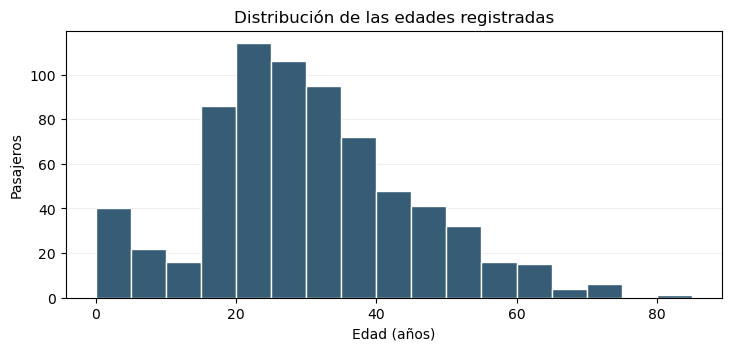

In [3]:
for variable in ["pclass", "sex", "survived"]:
    resumen = titanic[variable].value_counts().sort_index().rename("Registros").to_frame()
    resumen["Porcentaje"] = resumen["Registros"].div(len(titanic)).mul(100).round(1)
    display(resumen)

variables_numericas = {
    "age": "Edad (años)",
    "fare": "Tarifa",
    "sibsp": "Hermanos y cónyuges a bordo",
    "parch": "Padres e hijos a bordo",
}
resumen_numerico = titanic[list(variables_numericas)].describe().rename(columns=variables_numericas)
display(resumen_numerico.round(2))

edades_observadas = titanic["age"].dropna()

fig, ax = plt.subplots(figsize=(7.2, 3.4), layout="constrained")
ax.hist(edades_observadas, bins=range(0, 86, 5), color="#365d75", edgecolor="white")
ax.set(title="Distribución de las edades registradas", xlabel="Edad (años)", ylabel="Pasajeros")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=.2)
plt.show()

Hay **342 supervivientes de 891 registros (38,4 %)**. Tercera clase es el grupo más numeroso, con 491 registros. `describe()` cuenta **714 edades válidas** y **891 valores** en cada una de las otras tres variables numéricas del resumen. Las 714 edades observadas se usan en el histograma y tienen una mediana de 28 años. La cobertura completa de clase, sexo y desenlace permite conservar toda la base en P1 y P2. Para P3 se calcula primero la cobertura por grupo y se resumen las edades disponibles.

## V. Decisiones y transformaciones iniciales

| Decisión | Motivo | Resultado intermedio |
|---|---|---|
| Conservar las filas con valores idénticos. | El CSV carece de un identificador único para distinguir pasajeros con los mismos valores registrados. | Se conservan 891 filas, incluidas las 107 que coinciden con alguna anterior. |
| Usar `pclass` y `survived` y añadir etiquetas legibles. | Los códigos simplifican los cálculos y las etiquetas facilitan la lectura de las tablas. | Se verifica la equivalencia con `class` y `alive` en las 891 filas. `Clase` es una categoría ordenada de primera a tercera. |
| Analizar la supervivencia con todos los registros para P1 y P2. | Clase, sexo registrado y desenlace están completos. | Ambas comparaciones parten de 891 pasajeros registrados y 342 supervivientes. Los totales se comprueban en la sección VI. |
| Crear `Edad faltante` y resumir la edad observada sin imputación para P3. | La cobertura puede variar por clase y desenlace. | Se identifican 714 edades observadas y 177 faltantes. Las tablas 4 y 5 informan denominadores y cobertura. |

In [4]:
clases = ["Primera", "Segunda", "Tercera"]
variables_principales = ["pclass", "sex", "survived"]
assert not titanic[variables_principales].isna().any().any()
assert set(titanic["pclass"]) == {1, 2, 3}
assert set(titanic["sex"]) == {"female", "male"}
assert set(titanic["survived"]) == {0, 1}
clases_equivalentes = titanic["pclass"].map({1: "First", 2: "Second", 3: "Third"}).eq(titanic["class"])
desenlaces_equivalentes = titanic["survived"].map({0: "no", 1: "yes"}).eq(titanic["alive"])
assert clases_equivalentes.all() and desenlaces_equivalentes.all()

analisis = titanic.loc[:, variables_principales + ["age"]].copy()
analisis["Clase"] = pd.Categorical(
    analisis["pclass"].map(dict(enumerate(clases, start=1))),
    categories=clases,
    ordered=True,
)
analisis["Sexo registrado"] = analisis["sex"].map({"female": "Femenino", "male": "Masculino"})
analisis["Desenlace"] = analisis["survived"].map({0: "Falleció", 1: "Sobrevivió"})
analisis["Edad faltante"] = analisis["age"].isna()

print(f"Base de análisis: {len(analisis)} registros.")
print(f"Edades observadas: {analisis['age'].count()}. Edades faltantes: {analisis['Edad faltante'].sum()}.")
print(f"Equivalencia pclass/class: {clases_equivalentes.sum()} de {len(titanic)} registros.")
print(f"Equivalencia survived/alive: {desenlaces_equivalentes.sum()} de {len(titanic)} registros.")
display(analisis[["pclass", "Clase", "Sexo registrado", "Desenlace", "age", "Edad faltante"]].head())

Base de análisis: 891 registros.
Edades observadas: 714. Edades faltantes: 177.
Equivalencia pclass/class: 891 de 891 registros.
Equivalencia survived/alive: 891 de 891 registros.


,pclass,Clase,Sexo registrado,Desenlace,age,Edad faltante
0,3,Tercera,Masculino,Falleció,22.0,False
1,1,Primera,Femenino,Sobrevivió,38.0,False
2,3,Tercera,Femenino,Sobrevivió,26.0,False
3,1,Primera,Femenino,Sobrevivió,35.0,False
4,3,Tercera,Masculino,Falleció,35.0,False


## VI. Resultados e interpretación inicial

### P1 y P2 — Supervivencia por clase del pasaje y sexo registrado

En cada grupo, se divide el número de supervivientes por el total de registros. La brecha entre primera y tercera se calcula restando las tasas antes de redondear.

,Pasajeros,Supervivientes,Supervivencia (%)
Clase,,,
Primera,216,136,63.0
Segunda,184,87,47.3
Tercera,491,119,24.2


,Brecha primera − tercera (pp)
Total,38.7
Femenino,46.8
Masculino,23.3


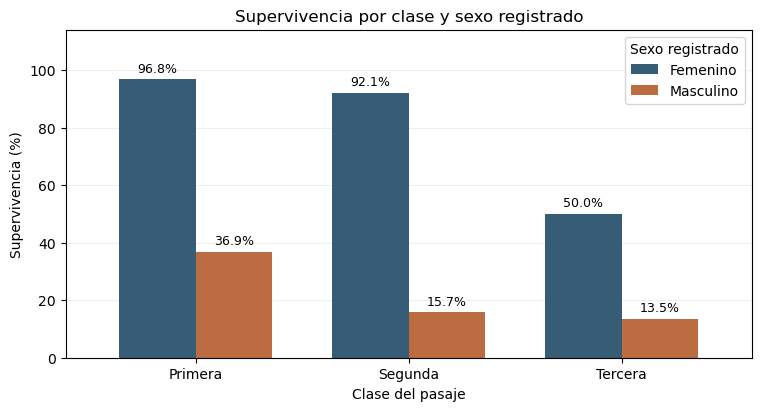

In [5]:
def proporciones_supervivencia(por):
    tabla = analisis.groupby(por, observed=True)["survived"].agg(
        Pasajeros="size", Supervivientes="sum",
    )
    tabla["Supervivencia (%)"] = tabla["Supervivientes"].div(tabla["Pasajeros"]).mul(100)
    return tabla

por_clase = proporciones_supervivencia("Clase")
por_clase_sexo = proporciones_supervivencia(["Clase", "Sexo registrado"])
assert por_clase["Pasajeros"].sum() == por_clase_sexo["Pasajeros"].sum() == len(analisis)
assert por_clase["Supervivientes"].sum() == por_clase_sexo["Supervivientes"].sum() == 342

display(por_clase.style.format(precision=1).set_caption("Tabla 1. Supervivencia por clase del pasaje"))
display(por_clase_sexo.style.format(precision=1).set_caption("Tabla 2. Supervivencia por clase y sexo registrado"))

tasas = por_clase_sexo["Supervivencia (%)"].unstack().reindex(clases)
brechas = pd.Series({
    "Total": por_clase.loc["Primera", "Supervivencia (%)"] - por_clase.loc["Tercera", "Supervivencia (%)"],
    "Femenino": tasas.loc["Primera", "Femenino"] - tasas.loc["Tercera", "Femenino"],
    "Masculino": tasas.loc["Primera", "Masculino"] - tasas.loc["Tercera", "Masculino"],
}, name="Brecha primera − tercera (pp)")
display(brechas.to_frame().style.format(precision=1).set_caption("Tabla 3. Brecha de supervivencia entre primera y tercera"))

fig, ax = plt.subplots(figsize=(7.5, 4), layout="constrained")
tasas.plot.bar(ax=ax, color=["#365d75", "#bb6c40"], rot=0, width=.72)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f%%", fontsize=9, padding=3)
ax.set(title="Supervivencia por clase y sexo registrado", xlabel="Clase del pasaje",
       ylabel="Supervivencia (%)", ylim=(0, 114), yticks=range(0, 101, 20))
ax.legend(title="Sexo registrado", loc="upper right")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=.2)
plt.show()

**P1 (tablas 1 y 3).** Sobrevivió el **63,0 %** de primera clase, el **47,3 %** de segunda y el **24,2 %** de tercera. La brecha entre primera y tercera fue de **38,7 puntos porcentuales**.

**P2 (tablas 2 y 3).** La brecha entre primera y tercera se observa en ambas categorías de sexo registrado. Fue de **46,8 pp** en la categoría femenina y de **23,3 pp** en la masculina. La mayor caída entre clases consecutivas se observa entre segunda y tercera en la categoría femenina, y entre primera y segunda en la masculina. Estas categorías incluyen a menores de edad.

### P3 — Edad observada y faltantes

Calculamos la mediana de las edades registradas y el porcentaje de edades faltantes por clase y desenlace (tabla 4) y para el total de cada desenlace (tabla 5). El porcentaje de faltantes usa todos los registros del grupo como denominador. La mediana usa únicamente las edades disponibles.

In [6]:
def resumen_edad(por):
    tabla = analisis.groupby(por, observed=True).agg(
        Pasajeros=("age", "size"),
        Edades_observadas=("age", "count"),
        Edades_faltantes=("Edad faltante", "sum"),
        Mediana_edad=("age", "median"),
    )
    tabla["Edad faltante (%)"] = tabla["Edades_faltantes"].div(tabla["Pasajeros"]).mul(100)
    return tabla


edad_por_grupo = resumen_edad(["Clase", "Desenlace"])
edad_por_desenlace = resumen_edad("Desenlace")
assert edad_por_grupo["Edades_faltantes"].sum() == edad_por_desenlace["Edades_faltantes"].sum() == 177
assert edad_por_grupo["Edades_observadas"].sum() == edad_por_desenlace["Edades_observadas"].sum() == 714

display(edad_por_grupo.style.format(precision=1).set_caption("Tabla 4. Edad por clase y desenlace"))
display(edad_por_desenlace.style.format(precision=1).set_caption("Tabla 5. Edad por desenlace"))

,Pasajeros,Edades_observadas,Edades_faltantes,Mediana_edad,Edad faltante (%)
Desenlace,,,,,
Falleció,549,424,125,28.0,22.8
Sobrevivió,342,290,52,28.0,15.2


**P3 (tablas 4 y 5).** La mediana de las edades observadas fue de **28 años** entre supervivientes (290 de 342 con edad registrada) y entre fallecidos (424 de 549). Entre los fallecidos faltó el **27,4 %** de las edades en tercera clase y el **7,2 %** en segunda. La coincidencia de las medianas globales resume los registros disponibles. Con esa cobertura desigual, sigue abierta la pregunta de cómo se distribuye la edad en el conjunto completo de pasajeros.

### Contexto histórico de la brecha

Buckley, pasajero de tercera clase, declaró ante el Senado estadounidense que alguien cerró con llave una reja hacia una cubierta de primera clase y que otro pasajero rompió la cerradura. Según su relato, tras romperse el cierre, quienes estaban allí pudieron subir. Abelseth, también de tercera, declaró que una reja cerrada impedía pasar por esa ruta y que se abrió cuando un oficial llamó a las mujeres a subir. Desconocía si tenía llave (Abelseth, 1912; Buckley, 1912, preguntas 14968–14974).

El informe británico reconoció la dificultad de subir desde los alojamientos de tercera y rechazó la existencia de trato preferente al embarcar en los botes. Hall (1986), en una revisión posterior, propuso que la ubicación de los botes, la atención prioritaria a primera y segunda clase y episodios de exclusión pudieron contribuir a la brecha. El anexo británico informó **63 %** de supervivencia en primera y **25 %** en tercera entre los pasajeros de su recuento. Se trata de una cobertura histórica diferente de la del CSV (British Wreck Commissioner's Inquiry, 1912a, 1912b).

## VII. Supuestos y limitaciones

- La clase del pasaje aproxima la posición económica. El CSV carece de ingresos o patrimonio individual, así como de las rutas de evacuación, la hora de llegada a cubierta y el acceso a cada bote. La contribución de cada mecanismo histórico queda sin identificar.
- Las tasas describen los pasajeros registrados en el CSV. El recuento histórico británico aporta contexto y tiene distintos denominadores.
- La falta de edad varía entre grupos. Las medianas se refieren a los registros con edad disponible y la cobertura desigual puede afectar la comparación. En la siguiente fase se podrá explorar este efecto por clase y desenlace.
- La ausencia de un identificador individual impide confirmar si las filas iguales corresponden a la misma persona. Se conservan todos los registros y se deja documentada esa decisión.

## VIII. Cierre del avance

La exploración inicial cuantifica una brecha de **38,7 pp** entre primera y tercera (tablas 1 y 3). La brecha aparece en ambas categorías de sexo registrado y es mayor en la femenina (tablas 2 y 3). La cobertura desigual de la edad acota la interpretación de las medianas (tablas 4 y 5). En la siguiente etapa se podrá examinar si los patrones se mantienen al comparar tramos de edad y documentar la sensibilidad de los resultados al tratamiento de los faltantes.

### Referencias

- Abelseth, O. (1912, 3 de mayo). *Testimony of Olaus Abelseth* [Testimonio ante el Senado de Estados Unidos]. Titanic Inquiry Project. https://www.titanicinquiry.org/USInq/AmInq13Abelseth01.php
- British Wreck Commissioner's Inquiry. (1912a). *Account of the saving and rescue of those who survived: Third class passengers* [Sección del informe oficial]. Titanic Inquiry Project. https://www.titanicinquiry.org/BOTInq/BOTReport/botRep3rdClass.php
- British Wreck Commissioner's Inquiry. (1912b). *Appendix: Passenger and crew numbers and percentages* [Anexo del informe oficial]. Titanic Inquiry Project. https://titanicinquiry.org/BOTInq/BOTApp/BOTApp01.php
- Buckley, D. (1912, 3 de mayo). *Testimony of Daniel Buckley* [Testimonio ante el Senado de Estados Unidos]. Titanic Inquiry Project. https://www.titanicinquiry.org/USInq2/AmInq13Buckley01.php
- Hall, W. (1986). Social class and survival on the S.S. Titanic. *Social Science & Medicine, 22*(6), 687–690. https://doi.org/10.1016/0277-9536(86)90041-9
- Waskom, M. (s. f.). *Titanic* [Conjunto de datos]. GitHub. https://github.com/mwaskom/seaborn-data/blob/71e2436a092d714350de0fc409ca8a8714e7e78f/titanic.csv